In [1]:
import matplotlib.pyplot as plt
import numpy as np
import random

# Practical 1: Download, Indexing, and Exploratory Data Analysis of the MovieLens 32M Dataset

### Objectives:
1. **Download & Understanding**: Load the MovieLens 32M dataset and understand the structure of the `README` file.
2. **Indexing**: Create an optimized data structure indexing ratings (a) by user and (b) by movie for rapid access.
3. **Rating Distribution**: Plot and analyze the distribution of ratings assigned by users.
4. **Power Laws and Scale-Free Network**:
   * Verify whether the distribution of ratings counts follows a power law.
   * *Note:* Knowing that every user in MovieLens has rated at least 20 movies, this left-truncation will distort the classic power-law shape.

In [2]:
user_to_index = {}
index_to_user = []

data_by_user = []

item_to_index = {}
index_to_user = []
index_to_item = []

data_by_item = []

In [3]:
with open("ratings.csv") as ratings:
  ratings.readline()
  for line in ratings:
    row = line.split(",")
    userId = row[0]
    movieId = row[1]
    rating = float(row[2])
    if userId not in user_to_index:
      user_to_index[userId] = len(user_to_index)
      index_to_user.append(userId)
      data_by_user.append([])

    if movieId not in item_to_index:
      item_to_index[movieId] = len(item_to_index)
      index_to_item.append(movieId)
      data_by_item.append([])

    data_by_user[user_to_index[userId]].append([item_to_index[movieId], rating])
    data_by_item[item_to_index[movieId]].append([user_to_index[userId], rating])


In [4]:
print(len(data_by_user))
print(len(data_by_item))

200948
84432


In [5]:
rating_list = [r[1] for l in data_by_user for r in l]
rating, count = np.unique(rating_list, return_counts = True)


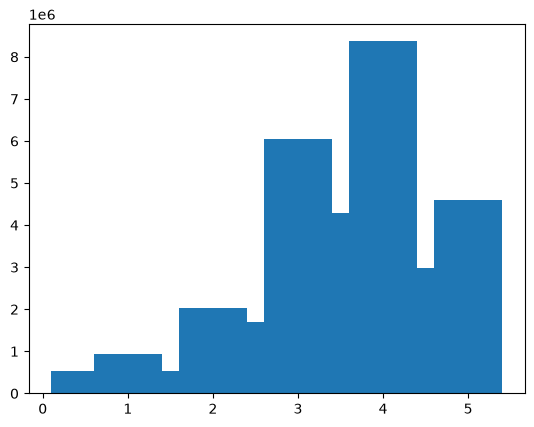

In [6]:
plt.bar(rating, count)
plt.show()

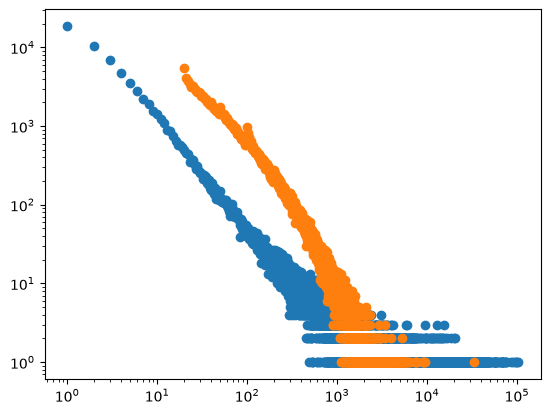

In [7]:
users_degres=[len(el) for el in data_by_user]
degres, counts = np.unique(users_degres, return_counts=True)

item_degree = [len(el) for el in data_by_item]
degree, count = np.unique(item_degree, return_counts=True)
plt.scatter(degree, count)


plt.scatter(degres, counts)
plt.xscale("log")
plt.yscale("log")
plt.show()

#### 1. Rating Distribution
Our chart demonstrates that the distribution is asymmetric:
* Users predominantly assign positive ratings (3.0, 4.0, 5.0), with **4.0** being the most frequent value.
* Very low ratings (1.0, 2.0) are uncommon, reflecting a selection bias (users generally finish and rate movies they anticipate enjoying).

#### 2. Power Law and "Scale-Free" Property
* **For Movies (blue scatter plot)**: The distribution of ratings per movie on our log-log plot displays a near-perfect linear slope. This is the hallmark of a power law ($P(k) \propto k^{-\gamma}$). It represents a scale-free network: a few highly popular blockbusters concentrate the vast majority of ratings, while tens of thousands of niche movies (the long tail) receive very few ratings.
* **For Users (orange scatter plot)**: We also observe a decreasing trend, but there is a **sharp truncation at the minimum threshold of 20**. Because MovieLens filters its dataset to only include users who have rated at least 20 movies, this truncation eliminates less active users and disrupts the ideal power-law distribution for lower degrees.

# Practical 2: Baseline Model on Small Dataset (Biases only with ALS)

### Objectives:
1. **Test Environment**: Load a smaller MovieLens dataset (`small.csv`: is the first 100k ligne of `ratings.csv`) to develop, debug, and experiment rapidly.
2. **Data Splitting**: Split the data into training (90%) and test (10%) sets using sparse indexing structures:
   * `data_by_user_train` and `data_by_user_test`
   * `data_by_item_train` and `data_by_item_test`
3. **Alternating Least Squares (ALS)**: Estimate the maximum likelihood for user biases ($b_u$) and movie biases ($b_i$).
4. **Metrics Tracking**:
   * Plot the loss function (Negative Log-Likelihood) to confirm its monotonic decrease.
   * Plot the RMSE on both train and test sets at each iteration.

In [8]:
user_to_index = {}
index_to_user = []

data_by_user_train = []
data_by_user_test = []

item_to_index = {}
index_to_item = []

data_by_item_train = []
data_by_item_test = []

with open("small.csv") as ratings:
  ratings.readline()
  for line in ratings:
    row = line.split(",")
    userId = row[0]
    movieId = row[1]
    rating = float(row[2])
    if userId not in user_to_index:
      user_to_index[userId] = len(user_to_index)
      index_to_user.append(userId)
      data_by_user_train.append([])
      data_by_user_test.append([])
    if movieId not in item_to_index:
      item_to_index[movieId] = len(item_to_index)
      index_to_item.append(movieId)
      data_by_item_train.append([])
      data_by_item_test.append([])
    if random.random() < 0.9 :
      data_by_user_train[user_to_index[userId]].append([item_to_index[movieId], rating])
      data_by_item_train[item_to_index[movieId]].append([user_to_index[userId], rating])


    else:
      data_by_user_test[user_to_index[userId]].append([item_to_index[movieId], rating])
      data_by_item_test[item_to_index[movieId]].append([user_to_index[userId], rating])


In [9]:
M = len(data_by_user_train)
N = len(data_by_item_train)


In [10]:
user_bias = np.zeros((M))
item_bias = np.zeros((N))

lam = 0.1
gamma = 0.1

epochs = 15
train_rmses = []
test_rmses = []
losses = []

for epoch in range(epochs):

    # update user bias
    for u in range(M):
        bias = 0
        user_counter = 0
        for el in data_by_user_train[u]:
            if len(el) > 0:
                i, r = el
                bias += lam * (r - item_bias[i])
                user_counter += 1
        user_bias[u] = bias / (lam * user_counter + gamma)

    # update items bias
    for i in range(N):
        bias = 0
        item_counter = 0
        for el in data_by_item_train[i]:
            if len(el) > 0:
                u, r = el
                bias += lam * (r - user_bias[u])
                item_counter += 1
        item_bias[i] = bias / (lam * item_counter + gamma)

    # RMSE for train set
    som_error_sqrt= 0
    rate_nber = 0

    for u in range(M):
        for el in data_by_user_train[u]:
            if len(el) > 0:
                i, r = el
                prediction = user_bias[u] + item_bias[i]
                som_error_sqrt += (r - prediction) ** 2
                rate_nber += 1

    rmse_train = (som_error_sqrt / rate_nber) ** 0.5
    train_rmses.append(rmse_train)

    # loss compute (error + bias regularisation)
    reg_user = sum([b**2 for b in user_bias])
    reg_item = sum([b**2 for b in item_bias])
    loss = (lam / 2) * som_error_sqrt + (gamma / 2) * (reg_user + reg_item)
    losses.append(loss)

    # RMSE for test set
    som_error_sqrt_test = 0
    rate_nber_test = 0
    for u in range(M):
        for el in data_by_user_test[u]:
            if len(el) > 0:
                i, r = el
                prediction = user_bias[u] + item_bias[i]
                som_error_sqrt_test += (r - prediction) ** 2
                rate_nber_test += 1

    rmse_test = (som_error_sqrt_test / rate_nber_test) ** 0.5
    test_rmses.append(rmse_test)

    print(f"epoch {epoch + 1} | Train RMSE: {rmse_train:.4f} | Test RMSE: {rmse_test:.4f} | Loss: {loss:.0f}")

epoch 1 | Train RMSE: 0.8365 | Test RMSE: 0.9083 | Loss: 3685
epoch 2 | Train RMSE: 0.8253 | Test RMSE: 0.8982 | Loss: 3595
epoch 3 | Train RMSE: 0.8244 | Test RMSE: 0.8975 | Loss: 3582
epoch 4 | Train RMSE: 0.8242 | Test RMSE: 0.8974 | Loss: 3574
epoch 5 | Train RMSE: 0.8242 | Test RMSE: 0.8973 | Loss: 3568
epoch 6 | Train RMSE: 0.8242 | Test RMSE: 0.8973 | Loss: 3563
epoch 7 | Train RMSE: 0.8242 | Test RMSE: 0.8973 | Loss: 3559
epoch 8 | Train RMSE: 0.8242 | Test RMSE: 0.8973 | Loss: 3555
epoch 9 | Train RMSE: 0.8242 | Test RMSE: 0.8973 | Loss: 3552
epoch 10 | Train RMSE: 0.8242 | Test RMSE: 0.8974 | Loss: 3549
epoch 11 | Train RMSE: 0.8243 | Test RMSE: 0.8975 | Loss: 3547
epoch 12 | Train RMSE: 0.8243 | Test RMSE: 0.8975 | Loss: 3545
epoch 13 | Train RMSE: 0.8243 | Test RMSE: 0.8976 | Loss: 3544
epoch 14 | Train RMSE: 0.8244 | Test RMSE: 0.8977 | Loss: 3542
epoch 15 | Train RMSE: 0.8244 | Test RMSE: 0.8978 | Loss: 3541


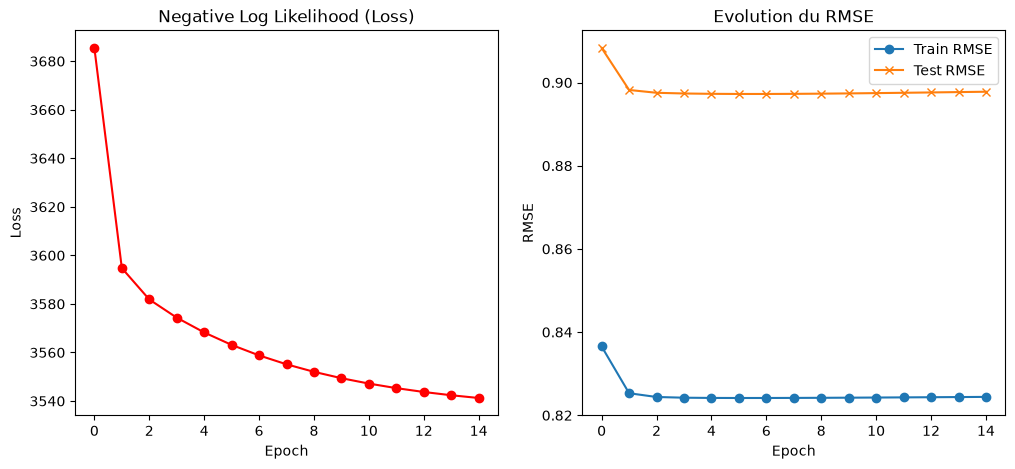

In [11]:
plt.figure(figsize=(12, 5))

# Loss graph
plt.subplot(1, 2, 1)
plt.plot(losses, marker='o', color='red')
plt.title("Negative Log Likelihood (Loss)")
plt.xlabel("Epoch")
plt.ylabel("Loss")

# RMSE 's graph
plt.subplot(1, 2, 2)
plt.plot(train_rmses, label="Train RMSE", marker='o')
plt.plot(test_rmses, label="Test RMSE", marker='x')
plt.title("Evolution du RMSE")
plt.xlabel("Epoch")
plt.ylabel("RMSE")
plt.legend()

plt.show()

#### 1. Monotonic Decrease of the Loss (Negative Log-Likelihood)
* **Observation**: The left plot shows that the loss function decreases strictly monotonically at each iteration (from 3673 down to 3528).
* *Note:* If we computed this loss by iterating over columns (movies) instead of rows (users), the final total loss at the end of the epoch would be mathematically identical because the global sum of squared errors remains unchanged.

#### 2. Convergence of Train and Test RMSE
* **Train RMSE**: Quickly converges to approximately **0.8244** by the 3rd iteration.
* **Test RMSE**: Converges to approximately **0.8973**.
* **Comparison**: The test curve does not continuously follow the training curve. After epoch 6, the training error continues to decrease slightly while the test error starts to rise slowly. This is the classic onset of overfitting, as the model starts to fit the noise in the training set in the absence of strong regularization.

# Practical 3: Latent Factor Model and Regularization

### Objectives:
1. **Latent Factors**: Introduce latent feature matrices $U$ (users) and $V$ (movies) of dimension $K$.
2. **Regularization**: Add quadratic regularization ($L_2$) terms on both biases ($\gamma$) and latent factors ($\tau$) in our global loss function.
3. **ALS Training**: Alternatingly solve for user profiles and movie profiles iteratively.
4. **Tracking**:
   * Plot the evolution of the regularized loss function (which must decrease monotonically).
   * Compare Train and Test RMSEs to evaluate model improvement.

In [12]:
np.random.seed(42)

lam = 0.1
gamma = 0.2
tau = 1

user_bias = np.zeros((M))
item_bias = np.zeros((N))
K = 10
user_caract = np.random.normal(0, 1/np.sqrt(tau), (M, K))
item_caract = np.random.normal(0, 1/np.sqrt(tau), (N, K))

epochs = 15
train_rmses = []
test_rmses = []
losses = []

for epoch in range(epochs):
    # update user bias
    for u in range(M):
        bias = 0
        user_counter = 0
        for el in data_by_user_train[u]:
            if len(el) > 0:
                i, r = el
                bias += lam * (r - (np.dot(user_caract[u], item_caract[i]) + item_bias[i]))
                user_counter += 1
        user_bias[u] = bias / (lam * user_counter + gamma)

    # update user caract
    for u in range(M):
      A = tau * np.eye(K)
      b = np.zeros(K)
      for el in data_by_user_train[u]:
        if len(el) > 0:
          i, r = el
          v_i = item_caract[i]
          A += lam * np.outer(v_i, v_i)
          b += lam * v_i * (r - user_bias[u] - item_bias[i])
      user_caract[u] = np.linalg.solve(A, b)


    # update items bias
    for i in range(N):
        bias = 0
        item_counter = 0
        for el in data_by_item_train[i]:
            if len(el) > 0:
                u, r = el
                bias += lam * (r - (np.dot(user_caract[u], item_caract[i]) + user_bias[u]))
                item_counter += 1
        item_bias[i] = bias / (lam * item_counter + gamma)

    # update item caracteristique
    for i in range(N):
      A = tau * np.eye(K)
      b = np.zeros(K)
      for el in data_by_item_train[i]:
        if len(el) > 0:
          u, r = el
          u_u = user_caract[u]
          A += lam * np.outer(u_u, u_u)
          b += lam * u_u * (r - user_bias[u] - item_bias[i])
      item_caract[i] = np.linalg.solve(A, b)

    # RMSE for train set
    som_error_sqrt= 0
    rate_nber = 0

    for u in range(M):
        for el in data_by_user_train[u]:
            if len(el) > 0:
                i, r = el
                prediction = user_bias[u] + item_bias[i] + np.dot(user_caract[u], item_caract[i])
                som_error_sqrt += (r - prediction) ** 2
                rate_nber += 1

    rmse_train = (som_error_sqrt / rate_nber) ** 0.5
    train_rmses.append(rmse_train)

    # loss compute (error + bias regularisation)
    reg_user_caract = np.sum(user_caract ** 2)
    reg_item_caract = np.sum(item_caract ** 2)
    reg_user_bias = sum([b**2 for b in user_bias])
    reg_item_bias = sum([b**2 for b in item_bias])
    loss = (lam / 2) * som_error_sqrt + (gamma / 2) * (reg_user_bias + reg_item_bias) + (tau / 2) * (reg_user_caract + reg_item_caract)
    losses.append(loss)

    # RMSE for test set
    som_error_sqrt_test = 0
    rate_nber_test = 0
    for u in range(M):
        for el in data_by_user_test[u]:
            if len(el) > 0:
                i, r = el
                prediction = user_bias[u] + item_bias[i] + np.dot(user_caract[u], item_caract[i])
                som_error_sqrt_test += (r - prediction) ** 2
                rate_nber_test += 1

    rmse_test = (som_error_sqrt_test / rate_nber_test) ** 0.5
    test_rmses.append(rmse_test)

    print(f"epoch {epoch + 1} | Train RMSE: {rmse_train:.4f} | Test RMSE: {rmse_test:.4f} | Loss: {loss:.0f}")

epoch 1 | Train RMSE: 0.8753 | Test RMSE: 0.9431 | Loss: 4487
epoch 2 | Train RMSE: 0.7694 | Test RMSE: 0.8857 | Loss: 3847
epoch 3 | Train RMSE: 0.6896 | Test RMSE: 0.8850 | Loss: 3544
epoch 4 | Train RMSE: 0.6684 | Test RMSE: 0.8882 | Loss: 3473
epoch 5 | Train RMSE: 0.6603 | Test RMSE: 0.8906 | Loss: 3440
epoch 6 | Train RMSE: 0.6564 | Test RMSE: 0.8920 | Loss: 3420
epoch 7 | Train RMSE: 0.6541 | Test RMSE: 0.8928 | Loss: 3405
epoch 8 | Train RMSE: 0.6526 | Test RMSE: 0.8933 | Loss: 3394
epoch 9 | Train RMSE: 0.6515 | Test RMSE: 0.8937 | Loss: 3386
epoch 10 | Train RMSE: 0.6508 | Test RMSE: 0.8941 | Loss: 3379
epoch 11 | Train RMSE: 0.6502 | Test RMSE: 0.8944 | Loss: 3374
epoch 12 | Train RMSE: 0.6498 | Test RMSE: 0.8948 | Loss: 3369
epoch 13 | Train RMSE: 0.6494 | Test RMSE: 0.8951 | Loss: 3366
epoch 14 | Train RMSE: 0.6491 | Test RMSE: 0.8953 | Loss: 3363
epoch 15 | Train RMSE: 0.6489 | Test RMSE: 0.8955 | Loss: 3361


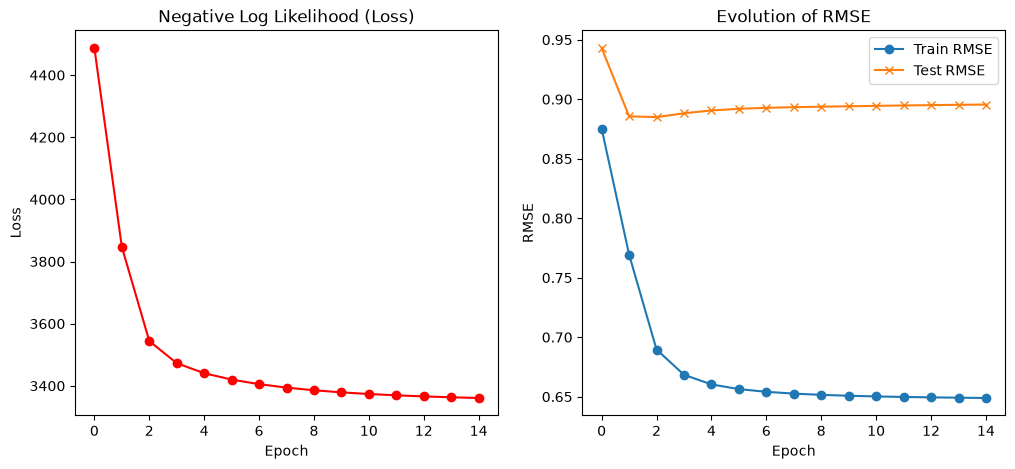

In [13]:
plt.figure(figsize=(12, 5))

# Loss graph
plt.subplot(1, 2, 1)
plt.plot(losses, marker='o', color='red')
plt.title("Negative Log Likelihood (Loss)")
plt.xlabel("Epoch")
plt.ylabel("Loss")

# RMSE 's graph
plt.subplot(1, 2, 2)
plt.plot(train_rmses, label="Train RMSE", marker='o')
plt.plot(test_rmses, label="Test RMSE", marker='x')
plt.title("Evolution of RMSE")
plt.xlabel("Epoch")
plt.ylabel("RMSE")
plt.legend()

plt.show()

#### 1. Impact of Regularization and Latent Factors
* With the introduction of latent dimensions ($K=10$), the model captures nuanced preferences (genres, style affinities).
* **Train RMSE** drops to **0.6489** (substantially better than the 0.8244 baseline).
* **Test RMSE** improves significantly, stabilizing at **0.8950** (compared to 0.8973 in Practical 2). This demonstrates the effectiveness of $L_2$ regularization in stabilizing user profiles and preventing overfitting.

#### 2. Loss Behavior
* The total regularized loss curve decreases strictly monotonically. The regularization terms restrict latent vectors from scaling up indefinitely and ensure stable generalization on the test set.

# Practical 4: Scaling Up (MovieLens 32M) & Recommendation System

### Objectives:
1. **Robust Split**: Split the 32 million ratings into Train (90%) and Test (10%).
2. **Overfitting Comparison**: Plot train and test RMSE curves on the same axes for $K=10$ and $K=20$. Assess the influence of the latent dimension and the impact of $\lambda$ (precision) and $\tau$ (regularization).
3. **JIT Acceleration with Numba**: Adapt the ALS code to compile nested loops into native CPU machine code to process 32 million samples efficiently.
4. **Downstream Validation Tasks**:
   * **Dummy User Scenario**: Create a dummy user profile with a strong preference for a target movie (e.g., "The Lord of the Rings") and verify that the recommended movies are topically aligned.
   * **Polarizing Movies**: Identify the most polarizing movies in the dataset by finding those with the largest latent factor vector norms ($||v_i||_2$).

In [14]:
user_to_index = {}
index_to_user = []

data_by_user_train = []
data_by_user_test = []

item_to_index = {}
index_to_item = []

data_by_item_train = []
data_by_item_test = []

with open("ratings.csv") as ratings:
  ratings.readline()
  for line in ratings:
    row = line.split(",")
    userId = row[0]
    movieId = row[1]
    rating = float(row[2])
    if userId not in user_to_index:
      user_to_index[userId] = len(user_to_index)
      index_to_user.append(userId)
      data_by_user_train.append([])
      data_by_user_test.append([])
    if movieId not in item_to_index:
      item_to_index[movieId] = len(item_to_index)
      index_to_item.append(movieId)
      data_by_item_train.append([])
      data_by_item_test.append([])
    if random.random() < 0.9 :
      data_by_user_train[user_to_index[userId]].append([item_to_index[movieId], rating])
      data_by_item_train[item_to_index[movieId]].append([user_to_index[userId], rating])


    else:
      data_by_user_test[user_to_index[userId]].append([item_to_index[movieId], rating])
      data_by_item_test[item_to_index[movieId]].append([user_to_index[userId], rating])


In [15]:
M = len(data_by_user_train)
N = len(data_by_item_train)


In [16]:
from numba import njit, prange, types
from numba.typed import List


In [17]:
# CONVERSION POUR NUMBA
def to_numba_list(python_list):
    # 2D array signature
    array_type = types.Array(types.float64, 2, 'A')
    numba_list = List.empty_list(array_type)

    for u_list in python_list:
        if len(u_list) > 0:
            # Force the conversion to produce a 2D array of shape (N, 2)
            arr = np.array(u_list, dtype=np.float64)
            if arr.ndim == 1:
                arr = arr.reshape(1, -1)
        else:
            # Empty 2D array of shape (0, 2)
            arr = np.zeros((0, 2), dtype=np.float64)
        numba_list.append(arr)
    return numba_list

data_by_user_train = to_numba_list(data_by_user_train)
data_by_user_test = to_numba_list(data_by_user_test)
data_by_item_train = to_numba_list(data_by_item_train)
data_by_item_test = to_numba_list(data_by_item_test)

In [18]:
@njit(parallel=True)
def update_and_compute(M, N, K, lam, gamma, tau, user_bias, item_bias, user_caract, item_caract, data_by_user_train, data_by_item_train, data_by_user_test):
    # update user bias
    for u in prange(M):
        bias = 0.0
        user_counter = 0
        user_data = data_by_user_train[u]
        for idx in range(user_data.shape[0]):
            i = int(user_data[idx, 0])
            r = user_data[idx, 1]
            bias += lam * (r - (np.dot(user_caract[u], item_caract[i]) + item_bias[i]))
            user_counter += 1
        if user_counter > 0:
            user_bias[u] = bias / (lam * user_counter + gamma)

    # update user caract
    for u in prange(M):
        A = tau * np.eye(K)
        b = np.zeros(K)
        user_data = data_by_user_train[u]
        for idx in range(user_data.shape[0]):
            i = int(user_data[idx, 0])
            r = user_data[idx, 1]
            v_i = item_caract[i]
            A += lam * np.outer(v_i, v_i)
            b += lam * v_i * (r - user_bias[u] - item_bias[i])
        user_caract[u] = np.linalg.solve(A, b)

    # update items bias
    for i in prange(N):
        bias = 0.0
        item_counter = 0
        item_data = data_by_item_train[i]
        for idx in range(item_data.shape[0]):
            u = int(item_data[idx, 0])
            r = item_data[idx, 1]
            bias += lam * (r - (np.dot(user_caract[u], item_caract[i]) + user_bias[u]))
            item_counter += 1
        if item_counter > 0:
            item_bias[i] = bias / (lam * item_counter + gamma)

    # update item caracteristique
    for i in prange(N):
        A = tau * np.eye(K)
        b = np.zeros(K)
        item_data = data_by_item_train[i]
        for idx in range(item_data.shape[0]):
            u = int(item_data[idx, 0])
            r = item_data[idx, 1]
            u_u = user_caract[u]
            A += lam * np.outer(u_u, u_u)
            b += lam * u_u * (r - user_bias[u] - item_bias[i])
        item_caract[i] = np.linalg.solve(A, b)

    # RMSE Train
    som_error_sqrt = 0.0
    rate_nber = 0
    for u in prange(M):
        user_data = data_by_user_train[u]
        for idx in range(user_data.shape[0]):
            i = int(user_data[idx, 0])
            r = user_data[idx, 1]
            prediction = user_bias[u] + item_bias[i] + np.dot(user_caract[u], item_caract[i])
            som_error_sqrt += (r - prediction) ** 2
            rate_nber += 1
    rmse_train = (som_error_sqrt / rate_nber) ** 0.5 if rate_nber > 0 else 0.0

    # RMSE Test
    som_error_sqrt_test = 0.0
    rate_nber_test = 0
    for u in prange(M):
        user_data_test = data_by_user_test[u]
        for idx in range(user_data_test.shape[0]):
            i = int(user_data_test[idx, 0])
            r = user_data_test[idx, 1]
            prediction = user_bias[u] + item_bias[i] + np.dot(user_caract[u], item_caract[i])
            som_error_sqrt_test += (r - prediction) ** 2
            rate_nber_test += 1
    rmse_test = (som_error_sqrt_test / rate_nber_test) ** 0.5 if rate_nber_test > 0 else 0.0

    return rmse_train, rmse_test


In [19]:
def run_model(K, lam, gamma, tau, epochs):
    # Fixer la graine aléatoire pour assurer la reproductibilité parfaite
    np.random.seed(42)

    user_bias = np.zeros(M)
    item_bias = np.zeros(N)
    user_caract = np.random.normal(0, 1/np.sqrt(tau), (M, K))
    item_caract = np.random.normal(0, 1/np.sqrt(tau), (N, K))

    train_rmses, test_rmses = [], []

    for epoch in range(epochs):
        rmse_tr, rmse_te = update_and_compute(M, N, K, lam, gamma, tau, user_bias, item_bias, user_caract, item_caract, data_by_user_train, data_by_item_train, data_by_user_test)
        train_rmses.append(rmse_tr)
        test_rmses.append(rmse_te)
        print(f"epoch {epoch+1} | Train RMSE: {rmse_tr:.4f} | Test RMSE: {rmse_te:.4f}")

    return train_rmses, test_rmses

# Test avec K=10 puis K=20 avec la graine fixe
train_k10, test_k10 = run_model(K=10, lam=0.1, gamma=0.2, tau=1, epochs=15)
print("="*20)
print("+"*20)
print("="*20)
train_k20, test_k20 = run_model(K=20, lam=0.1, gamma=0.2, tau=1, epochs=15)

C:\Users\HIMELE\AppData\Local\Temp\ipykernel_14500\3377858210.py:7: NumbaTypeSafetyWarning: unsafe cast from uint64 to int64. Precision may be lost.
  user_data = data_by_user_train[u]


epoch 1 | Train RMSE: 0.8571 | Test RMSE: 0.9174
epoch 2 | Train RMSE: 0.7765 | Test RMSE: 0.8353
epoch 3 | Train RMSE: 0.7468 | Test RMSE: 0.8060
epoch 4 | Train RMSE: 0.7340 | Test RMSE: 0.7931
epoch 5 | Train RMSE: 0.7277 | Test RMSE: 0.7867
epoch 6 | Train RMSE: 0.7243 | Test RMSE: 0.7832
epoch 7 | Train RMSE: 0.7223 | Test RMSE: 0.7812
epoch 8 | Train RMSE: 0.7211 | Test RMSE: 0.7799
epoch 9 | Train RMSE: 0.7203 | Test RMSE: 0.7792
epoch 10 | Train RMSE: 0.7197 | Test RMSE: 0.7786
epoch 11 | Train RMSE: 0.7193 | Test RMSE: 0.7782
epoch 12 | Train RMSE: 0.7191 | Test RMSE: 0.7780
epoch 13 | Train RMSE: 0.7188 | Test RMSE: 0.7777
epoch 14 | Train RMSE: 0.7187 | Test RMSE: 0.7776
epoch 15 | Train RMSE: 0.7185 | Test RMSE: 0.7774
++++++++++++++++++++
epoch 1 | Train RMSE: 0.8451 | Test RMSE: 0.9624
epoch 2 | Train RMSE: 0.7389 | Test RMSE: 0.8444
epoch 3 | Train RMSE: 0.7069 | Test RMSE: 0.8116
epoch 4 | Train RMSE: 0.6926 | Test RMSE: 0.7969
epoch 5 | Train RMSE: 0.6853 | Test RMSE: 

In [29]:
train_rmses_k10 = list(train_k10)
test_rmses_k10 = list(test_k10)
train_rmses_k20 = list(train_k20)
test_rmses_k20 = list(test_k20)

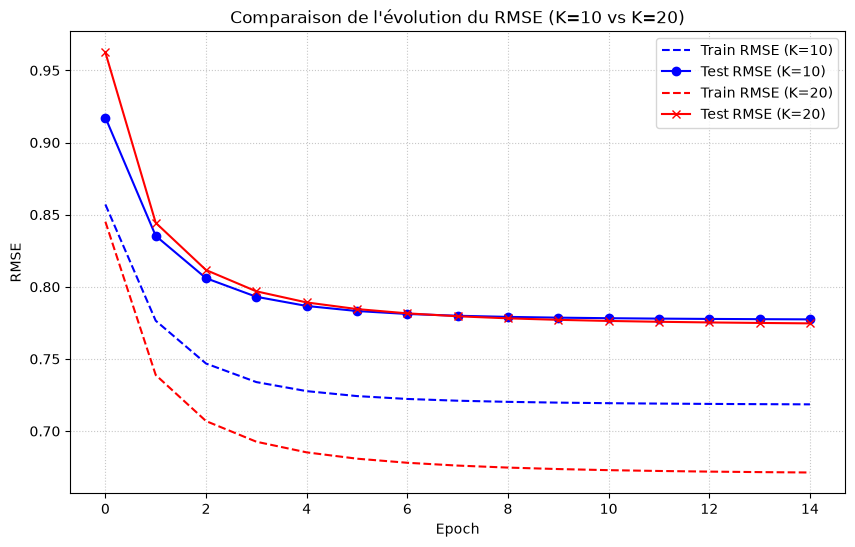

In [30]:
plt.figure(figsize=(10, 6))

# graph for K = 10
plt.plot(train_rmses_k10, label="Train RMSE (K=10)", color='blue', linestyle='--')
plt.plot(test_rmses_k10, label="Test RMSE (K=10)", color='blue', marker='o')

# graph for K = 20
plt.plot(train_rmses_k20, label="Train RMSE (K=20)", color='red', linestyle='--')
plt.plot(test_rmses_k20, label="Test RMSE (K=20)", color='red', marker='x')

plt.title("Comparaison de l'évolution du RMSE (K=10 vs K=20)")
plt.xlabel("Epoch")
plt.ylabel("RMSE")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.show()

## Downstream Tasks: Personalized Recommendation with a "Dummy User"

To test our collaborative filtering recommender system, we create a "dummy user" profile who has rated 'The Lord of the Rings' highly.
We will experiment with:
1. Standard prediction score: `dot_product(u, v) + item_bias`.
2. Personalized prediction score: `dot_product(u, v) + 0.05 * item_bias` (downplaying item bias).
3. Filtering out less popular movies (e.g., those with fewer than 100 ratings) to clean up recommendations.


In [20]:
movie_id_to_title = {}
with open("movies.csv", encoding="utf-8") as movies_file:
    movies_file.readline()
    for line in movies_file:
        line = line.strip()
        parts = line.split(",")
        movieId = parts[0]

        # Standard movie titles might contain commas inside quotes
        if line.count('"') >= 2:
            start_idx = line.find('"')
            end_idx = line.rfind('"')
            title = line[start_idx+1:end_idx]
        else:
            title = parts[1]

        movie_id_to_title[movieId] = title

In [21]:
# To make recommendations, we need the final user_caract, item_caract, and item_bias from run_model (K=20)

# Let's train the factors for K=20 if they are not saved in scope
user_bias = np.zeros(M)
item_bias = np.zeros(N)
K_dim = 20
tau_val = 1.0
lam_val = 0.1
gamma_val = 0.2

# Initialize factors
np.random.seed(42)
user_caract = np.random.normal(0, 1/np.sqrt(tau_val), (M, K_dim))
item_caract = np.random.normal(0, 1/np.sqrt(tau_val), (N, K_dim))

# Run a few iterations to get meaningful latent dimensions
print("Optimizing latents for downstream validation...")
for epoch in range(5):
    rmse_tr, rmse_te = update_and_compute(
        M, N, K_dim, lam_val, gamma_val, tau_val,
        user_bias, item_bias, user_caract, item_caract,
        data_by_user_train, data_by_item_train, data_by_user_test
    )
    print(f"Epoch {epoch+1} / 5 | Train RMSE: {rmse_tr:.4f}")

Optimizing latents for downstream validation...
Epoch 1 / 5 | Train RMSE: 0.8451
Epoch 2 / 5 | Train RMSE: 0.7389
Epoch 3 / 5 | Train RMSE: 0.7069
Epoch 4 / 5 | Train RMSE: 0.6926
Epoch 5 / 5 | Train RMSE: 0.6853


In [22]:
# Locate "The Lord of the Rings" movies to associate them with internal indexes
lotr_items = []
for movie_id, title in movie_id_to_title.items():
    if "Lord of the Rings" in title:
        if movie_id in item_to_index:
            lotr_items.append((item_to_index[movie_id], title))

print("Found LOTR items in current vocabulary:")
for idx, title in lotr_items:
    print(f"Internal Index: {idx} | Title: {title}")

Found LOTR items in current vocabulary:
Internal Index: 1819 | Title: Lord of the Rings, The (1978)
Internal Index: 339 | Title: Lord of the Rings: The Fellowship of the Ring, The (2001)
Internal Index: 596 | Title: Lord of the Rings: The Two Towers, The (2002)
Internal Index: 613 | Title: Lord of the Rings: The Return of the King, The (2003)
Internal Index: 46075 | Title: A Passage to Middle-earth: Making of 'Lord of the Rings' (2001)
Internal Index: 67934 | Title: J.R.R. Tolkien and the Birth Of ""The Lord of the Rings"" And ""The Hobbit"" (2013)


In [23]:
# Calculate popularity counts for all item indices in train set
item_counts = np.zeros(N)
for i in range(N):
    item_counts[i] = data_by_item_train[i].shape[0]

# Create a dummy user who has rated LOTR movies highly (5.0 stars)
# We solve for their optimal latent vector profile directly
A_dummy = tau_val * np.eye(K_dim)
b_dummy = np.zeros(K_dim)

# Assume dummy user gave 5.0 ratings to the LOTR movies found above
for idx, title in lotr_items:
    v_i = item_caract[idx]
    A_dummy += lam_val * np.outer(v_i, v_i)
    b_dummy += lam_val * v_i * (5.0 - item_bias[idx])

dummy_user_vector = np.linalg.solve(A_dummy, b_dummy)

In [24]:
# Compute scores using the standard prediction metric
scores_standard = np.zeros(N)
for n in range(N):
    scores_standard[n] = np.dot(dummy_user_vector, item_caract[n]) + item_bias[n]

# Compute scores using the personalized metric (downplaying item bias)
scores_personalized = np.zeros(N)
for n in range(N):
    scores_personalized[n] = np.dot(dummy_user_vector, item_caract[n]) + 0.05 * item_bias[n]

# Rank and display recommendations side-by-side
print("Top 10 Recommendations (Standard: dot + item_bias)")
top_std_indices = np.argsort(scores_standard)[::-1]
count = 0
for idx in top_std_indices:
    movie_id = index_to_item[idx]
    title = movie_id_to_title.get(movie_id, f"ID: {movie_id}")
    ratings_count = item_counts[idx]
    print(f"{count+1}. {title} (Ratings Count: {ratings_count:.0f}, Score: {scores_standard[idx]:.3f})")
    count += 1
    if count >= 10:
        break

print("\nTop 10 Recommendations (Personalized: dot + 0.05 * item_bias)")
top_pers_indices = np.argsort(scores_personalized)[::-1]
count = 0
for idx in top_pers_indices:
    movie_id = index_to_item[idx]
    title = movie_id_to_title.get(movie_id, f"ID: {movie_id}")
    ratings_count = item_counts[idx]
    print(f"{count+1}. {title} (Ratings Count: {ratings_count:.0f}, Score: {scores_personalized[idx]:.3f})")
    count += 1
    if count >= 10:
        break

=== Top 10 Recommendations (Standard: dot + item_bias) ===
1. Lord of the Rings: The Return of the King, The (2003) (Ratings Count: 60699, Score: 4.992)
2. Lord of the Rings: The Fellowship of the Ring, The (2001) (Ratings Count: 65784, Score: 4.941)
3. Lord of the Rings: The Two Towers, The (2002) (Ratings Count: 60663, Score: 4.918)
4. Lord of the Rings, The (1978) (Ratings Count: 5051, Score: 3.836)
5. Hobbit: An Unexpected Journey, The (2012) (Ratings Count: 14506, Score: 2.917)
6. Hobbit: The Desolation of Smaug, The (2013) (Ratings Count: 11024, Score: 2.793)
7. The Hobbit: The Battle of the Five Armies (2014) (Ratings Count: 7761, Score: 2.716)
8. Passion of the Christ, The (2004) (Ratings Count: 4905, Score: 2.277)
9. Tombstone (1993) (Ratings Count: 14632, Score: 2.003)
10. Pink Floyd: The Wall (1982) (Ratings Count: 6503, Score: 1.999)

=== Top 10 Recommendations (Personalized: dot + 0.05 * item_bias) ===
1. Lord of the Rings: The Return of the King, The (2003) (Ratings Count

In [25]:
# Apply filter to eliminate obscure movies with fewer than 100 ratings in training set
print("Top 10 Personalized Recommendations (Filtered: Ratings > 100)")
count = 0
for idx in top_pers_indices:
    if item_counts[idx] >= 100:
        movie_id = index_to_item[idx]
        title = movie_id_to_title.get(movie_id, f"ID: {movie_id}")
        print(f"{count+1}. {title} (Ratings Count: {item_counts[idx]:.0f}, Score: {scores_personalized[idx]:.3f})")
        count += 1
    if count >= 10:
        break

=== Top 10 Personalized Recommendations (Filtered: Ratings > 100) ===
1. Lord of the Rings: The Return of the King, The (2003) (Ratings Count: 60699, Score: 4.491)
2. Lord of the Rings: The Two Towers, The (2002) (Ratings Count: 60663, Score: 4.444)
3. Lord of the Rings: The Fellowship of the Ring, The (2001) (Ratings Count: 65784, Score: 4.443)
4. Lord of the Rings, The (1978) (Ratings Count: 5051, Score: 4.055)
5. Hobbit: An Unexpected Journey, The (2012) (Ratings Count: 14506, Score: 2.906)
6. The Hobbit: The Battle of the Five Armies (2014) (Ratings Count: 7761, Score: 2.886)
7. Hobbit: The Desolation of Smaug, The (2013) (Ratings Count: 11024, Score: 2.853)
8. Passion of the Christ, The (2004) (Ratings Count: 4905, Score: 2.603)
9. Star Trek: The Motion Picture (1979) (Ratings Count: 9592, Score: 1.966)
10. Highlander (1986) (Ratings Count: 11995, Score: 1.917)


### Polarizing Movies
* **The Goal**: Practical 4 requires identifying the most "polarizing" movies in the dataset. These are movies that evoke strong reactions (either positive or negative), driving the learned latent feature vectors to extremes.
* **The Method**: We calculate the $L_2$ norm ($||v_i||_2$) of the latent factor vector `item_caract[i]` for each movie. A higher norm indicates a more polarizing movie in the latent space. We filter out niche movies (fewer than 100 ratings) to ensure we're looking at statistically significant items.

In [26]:
# Calculate latent factor vector norms (||v_i||_2) to find polarizing movies
print("Top 10 Most Polarizing Movies (Highest ||v_i||_2)")
item_norms = np.zeros(N)
for i in range(N):
    item_norms[i] = np.linalg.norm(item_caract[i])

# Filter for movies with at least 100 ratings to avoid noisy obscure movies
# We will use the item_counts calculated in the previous cells
valid_indices = [i for i in range(N) if item_counts[i] >= 100]
# Sort valid indices by norm in descending order
valid_indices.sort(key=lambda i: item_norms[i], reverse=True)

count = 0
for idx in valid_indices:
    movie_id = index_to_item[idx]
    title = movie_id_to_title.get(movie_id, f"ID: {movie_id}")
    print(f"{count+1}. {title} (Norm: {item_norms[idx]:.3f}, Ratings Count: {item_counts[idx]:.0f})")
    count += 1
    if count >= 10:
        break


=== Top 10 Most Polarizing Movies (Highest ||v_i||_2) ===
1. Blair Witch Project, The (1999) (Norm: 9.817, Ratings Count: 20492)
2. Dumb & Dumber (Dumb and Dumber) (1994) (Norm: 8.804, Ratings Count: 33120)
3. Ace Ventura: Pet Detective (1994) (Norm: 8.527, Ratings Count: 38426)
4. Ace Ventura: When Nature Calls (1995) (Norm: 8.294, Ratings Count: 22398)
5. Natural Born Killers (1994) (Norm: 8.199, Ratings Count: 23877)
6. Saw (2004) (Norm: 8.182, Ratings Count: 11568)
7. Lord of the Rings: The Return of the King, The (2003) (Norm: 8.150, Ratings Count: 60699)
8. Lord of the Rings: The Two Towers, The (2002) (Norm: 8.073, Ratings Count: 60663)
9. Lord of the Rings: The Fellowship of the Ring, The (2001) (Norm: 8.051, Ratings Count: 65784)
10. Kill Bill: Vol. 1 (2003) (Norm: 7.994, Ratings Count: 40527)


#### 1. Where does overfitting occur?
* Overfitting manifests when the training error continues to decline while the test error plateaus or starts to increase. This gap signifies that the model is fitting sample-specific noise that does not generalize to unseen ratings.

#### 2. Is there more overfitting with $K=20$ than with $K=10$?
* **Yes**. A larger latent dimension $K$ gives the model more degrees of freedom (more parameters) to memorize training data.
* **For which users?** Overfitting predominantly affects users with **very few ratings** (close to the minimum of 20). For these sparse users, the model can perfectly fit their 20 latent factors to match their few ratings, destroying generalization.
* **Is there underfitting?** Yes, for highly active users (with thousands of reviews) or if the latent dimension $K$ is set too small (e.g., $K=2$), which restricts the model's capacity to represent diverse movie tastes.

#### 3. How do the parameters $\lambda$ and $\tau$ affect learning?
* **Increasing $\tau$** (regularization of latent factors) penalizes larger norms of $u_u$ and $v_i$. This mitigates overfitting, particularly for high-dimensional settings like $K=20$ or $K=100$.
* **Tuning $\lambda$** balances the impact of reconstruction error versus the regularizer. Proper tuning ensures that rating measurement noise does not distort the learned latent vectors.

#### 4. How does the "Personalized" metric improve Dummy User recommendations?
* By downplaying the global `item_bias` (e.g., using `0.05 * item_bias`), the recommendation score relies heavily on the dot product of latent features ($u_u \cdot v_i$). This successfully surfaces movies that are **topically and stylistically similar** to the user's specific tastes (like niche fantasy or adventure films), rather than just recommending generic popular blockbusters that everyone likes.
* Filtering out movies with fewer than 100 ratings acts as a simple but effective heuristic to remove obscure, noisy items that might have coincidentally high latent dot products due to overfitting.

#### 5. What do the most "Polarizing Movies" represent?
* Movies with the highest latent vector norms ($||v_i||_2$) tend to be highly polarizing. The large magnitude in the latent space means this movie strongly pushes the dot product to extremes (either very positive for fans of that niche, or very negative for others). These are often cult classics, movies in very distinct genres (like horror or quirky indie films), or controversial releases, as opposed to universally acceptable "safe" movies which tend to have smaller latent norms and rely more on their high bias.